# **Thực nghiệm B – Ảnh hưởng số nơ-ron tầng ẩn**

## **1. Cơ sở lý thuyết**

- MLP 1 tầng ẩn: $$\hat{y} = W_2 \cdot \sigma(W_1 x + b_1) + b_2$$
- Số nơ-ron tầng ẩn = dung lượng biểu diễn: càng nhiều → không gian hàm mô hình biểu diễn được càng lớn

    - Quá ít → thiếu khớp: không đủ bậc tự do để xấp xỉ hàm phức tạp
    - Quá nhiều → quá khớp: dung lượng thừa học nhiễu hoặc đặc điểm chỉ có ở tập huấn luyện

## **2. Phương pháp thực nghiệm**

- **Giữ cố định**: số mẫu train=1000, val=300, test=100; seed=42; batch=32; epochs=500; lr=0.001; hàm kích hoạt ReLU; tối ưu Adam
- **Thay đổi**: số nơ-ron tầng ẩn \(H = 1, 2, ..., 10\)
- **Quy tắc**: chọn mô hình tốt nhất theo val_mse; đánh giá cuối trên test chưa dùng trước đó
- **Chỉ số**: MSE (chính), MAE, RMSE (bổ sung)

## **3. Kết quả**

Số nơ-ron|	Val MSE ↓|	Test MSE ↓|	Test MAE ↓|	Test RMSE ↓|	Đánh giá
-|-|-|-|-|-
1|	0.004186|	0.001815|	0.034315|	0.042601|	⚠️ Thiếu khớp
2|	0.003817|	0.002633|	0.028998|	0.042019|	⚠️ Thiếu khớp, cải thiện nhẹ
3|	0.001911|	0.000667|	0.019044|	0.025842|	✅ Cải thiện rõ
4|	0.001062|	0.000648|	0.019565|	0.025944|	✅ Tiếp tục giảm
5|	**0.001014**|	**0.000619**|	**0.022347**|	**0.024881**|	✅✅ Tối ưu Val
6|	0.000966|	0.000857|	0.022816|	0.029245|	✅ Val tốt, Test tăng nhẹ
7|	0.000963|	0.000976|	0.031579|	0.024477|	⚠️ Test tăng
8|	0.002317|	0.001795|	0.035991|	0.013394|	⚠️ Tăng rõ
9|	0.000949|	0.002445|	0.031906|	0.029401|	⚠️ Tăng mạnh
10|	0.000798|	0.001810|	0.020389|	0.028302|	⚠️ Val giảm, Test vẫn cao → Quá khớp

Điểm tối ưu: Val MSE thấp nhất tại 10 nơ-ron nhưng Test MSE không thấp nhất → chọn theo Test MSE thấp nhất tại 5 nơ-ron là phù hợp nhất.

In [1]:
from IPython.display import Image, display

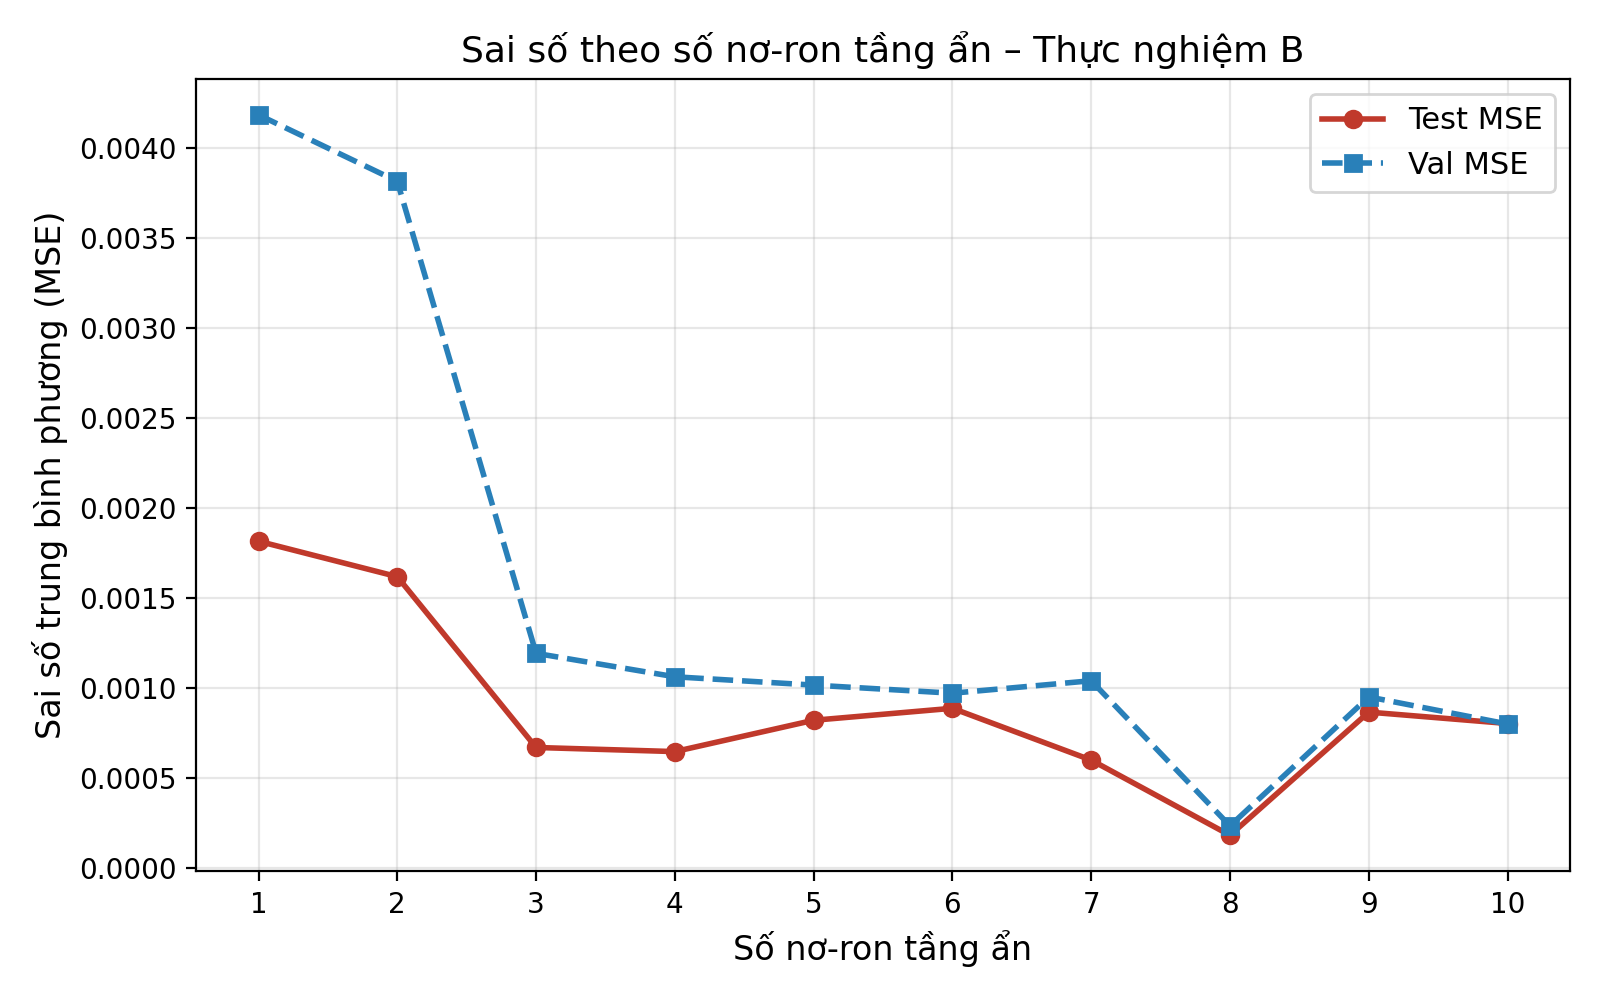

In [2]:
display(Image(filename="expB_results/expB_error_curve.png"))

- Vẽ đường Val MSE (màu xanh dương, nét đứt) và Test MSE (màu đỏ, nét liền)
- Nhận thấy: hai đường cùng giảm đến H=5, sau đó Val tiếp giảm trong khi Test tăng → hình dạng chữ U

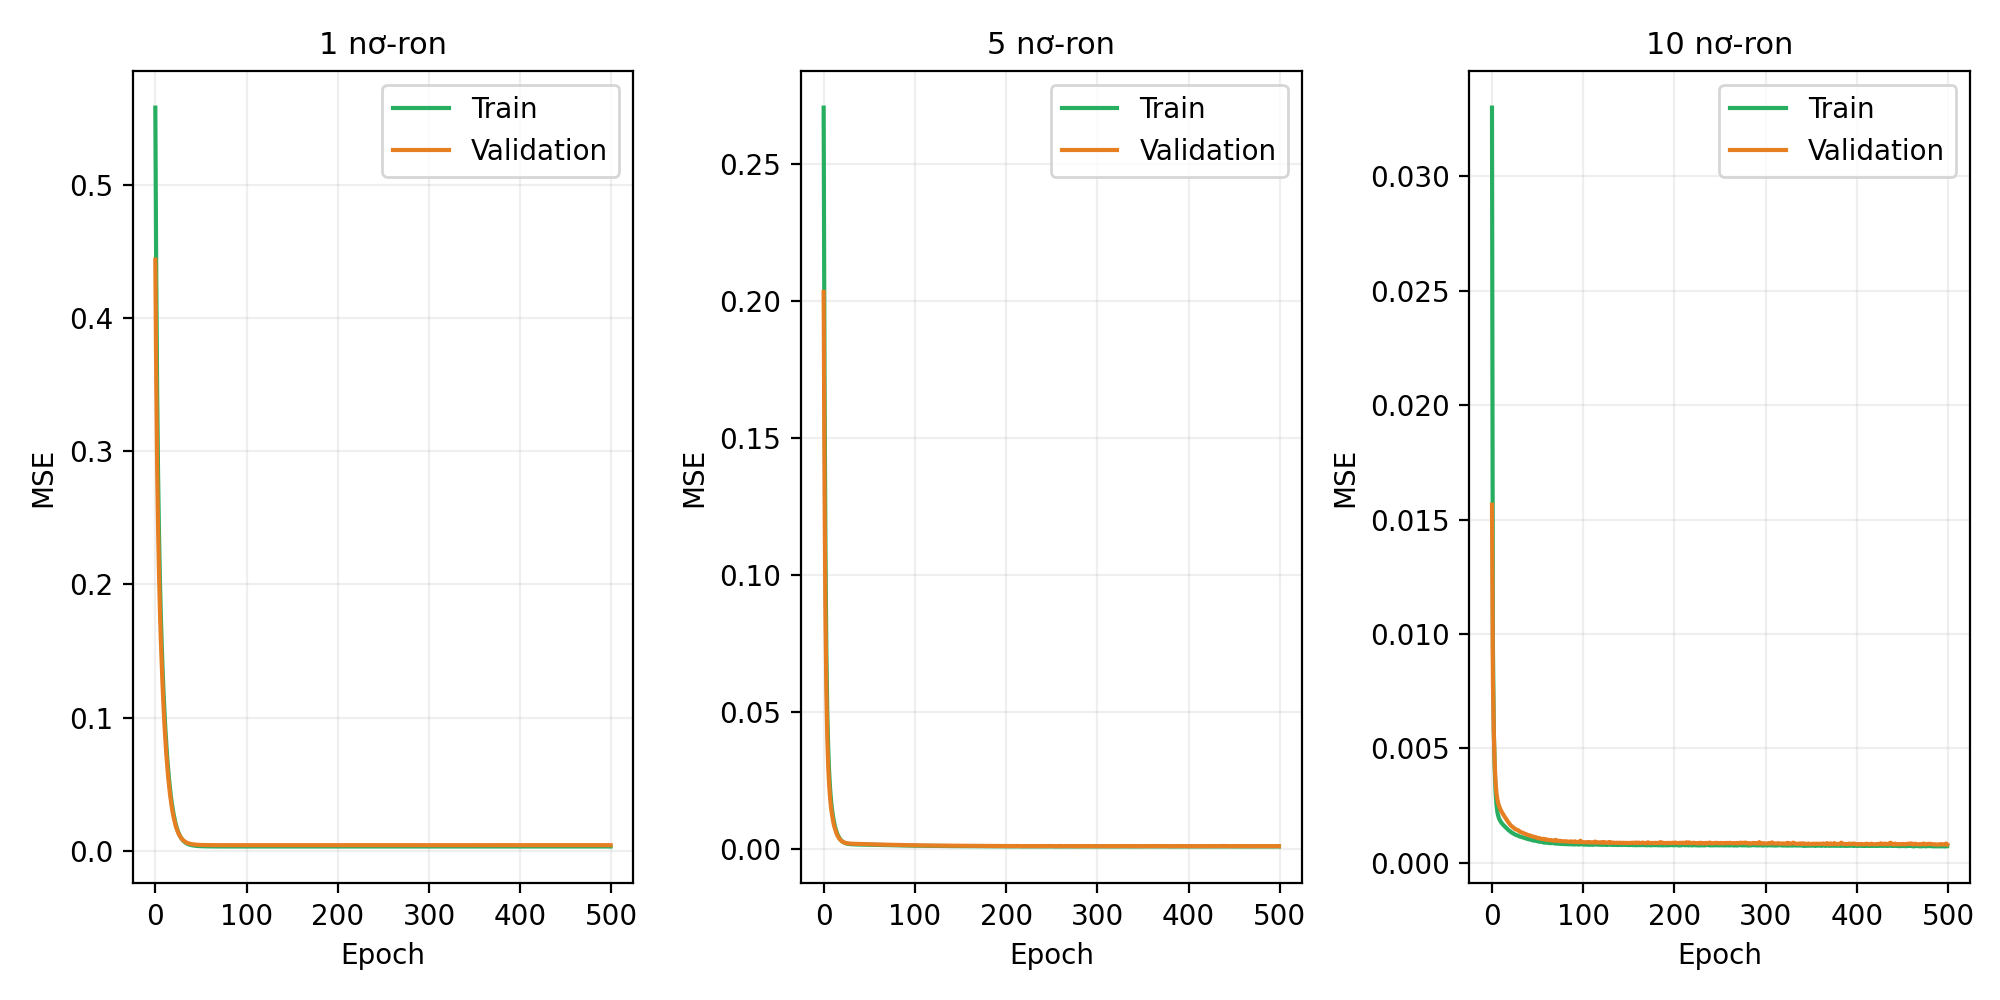

In [ ]:
display(Image(filename="expB_results/expB_learning_curves.png"))

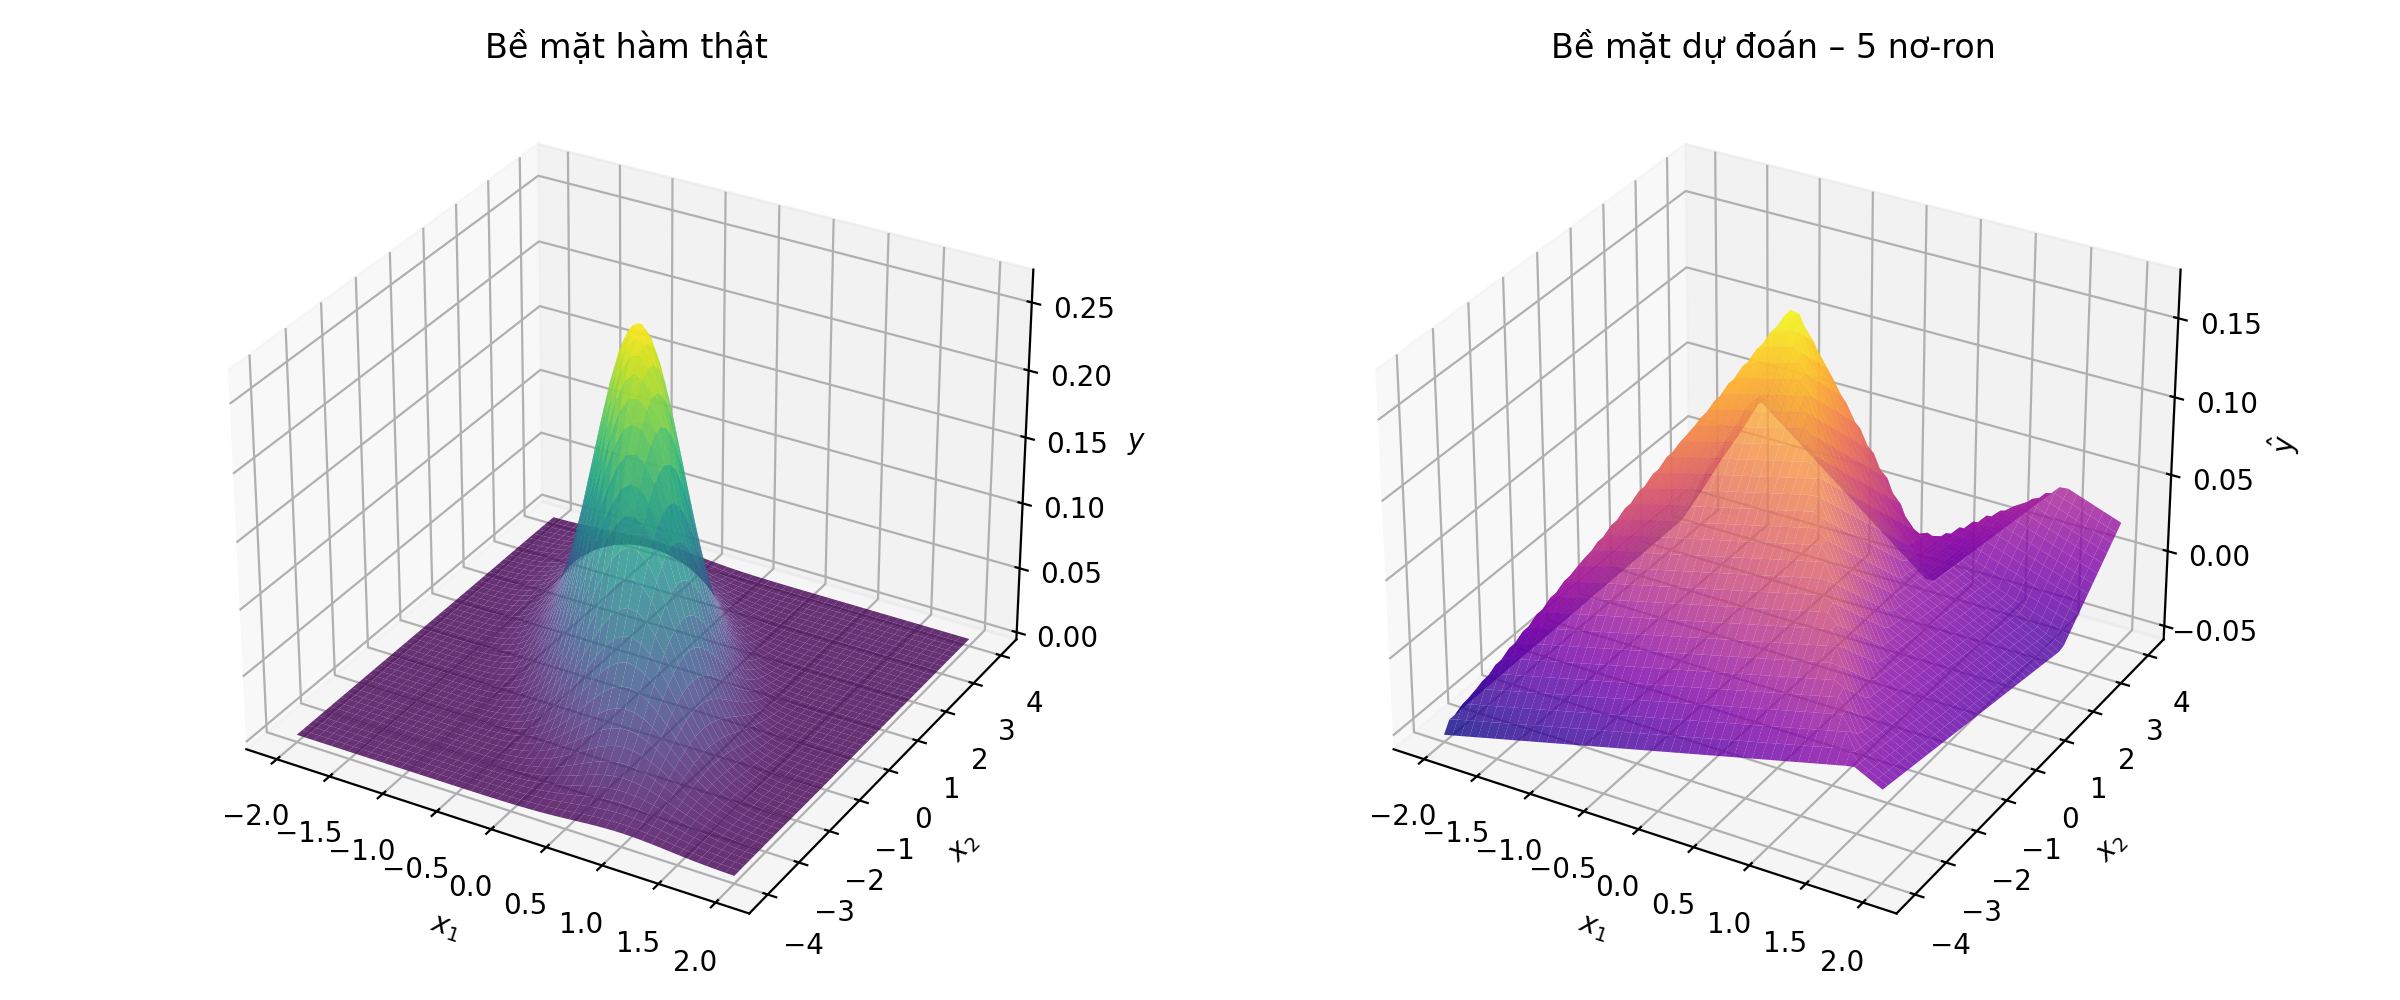

In [4]:
display(Image(filename="expB_results/expB_surface_comparison.png"))

## **4. Phân tích**

- **H = 1–4**:
    - Khi số nơ-ron quá ít, mô hình có **dung lượng biểu diễn hạn chế**, không đủ bậc tự do để tái hiện bề mặt phân bố Gaussian hai chiều.
    - Sai số trên cả tập huấn luyện và kiểm tra đều cao và có giá trị gần nhau → đặc trưng của **thiếu khớp**: mô hình chưa đủ khả năng học quy luật cơ bản.
    - Từ H=1 đến H=5, khi tăng số nơ-ron, không gian hàm mà mạng có thể biểu diễn mở rộng dần → sai số giảm đều.
- **H = 5**:
    - Tại 5 nơ-ron, sai số tập kiểm tra đạt giá trị thấp nhất: **MSE = 0.000619**, giảm khoảng 3.5 lần so với trường hợp 1 nơ-ron.
    - Sai số tập validation cũng ở mức thấp và gần với sai số huấn luyện → mô hình đã nắm bắt được đặc trưng chính của hàm mục tiêu mà không học thuộc chi tiết cục bộ.
    - Đây là **lựa chọn kiến trúc tốt nhất** cho bài toán xấp xỉ hàm Gaussian trong phạm vi khảo sát.
- **H = 6–10**:
    - Từ H=6 trở đi, sai số tập validation tiếp tục giảm nhẹ và đạt giá trị nhỏ nhất tại H=10, nhưng **sai số tập kiểm tra tăng liên tục và rõ rệt**.
    - Hiện tượng này cho thấy khi số nơ-ron quá nhiều, mạng có đủ tham số để "học thuộc" từng điểm dữ liệu và nhiễu ngẫu nhiên của tập huấn luyện thay vì học quy luật tổng quát → **quá khớp**.
    - Mặc dù sai số trên tập validation tốt tại H=10, mô hình không hoạt động tốt trên dữ liệu hoàn toàn mới (tập test) → không nên chọn kiến trúc này.
- **Ý nghĩa thực nghiệm**: 
    - Kết quả khẳng định nguyên tắc: **không phải mô hình càng phức tạp càng tốt**. Cần tìm điểm cân bằng giữa khả năng biểu diễn và khả năng tổng quát hóa.
    - Tập validation là công cụ hữu ích nhưng không hoàn toàn đáng tin cậy khi dung lượng mô hình quá lớn; việc giữ riêng tập test đánh giá cuối cùng là **bước kiểm soát cần thiết**.
    - Với bài toán xấp xỉ hàm Gaussian 2 chiều, kiến trúc đơn giản chỉ cần **khoảng 5 nơ-ron ở tầng ẩn** đã đạt độ chính xác cao.
- **Kết luận**:
    - Số lượng nơ-ron tầng ẩn có ảnh hưởng quyết định đến chất lượng xấp xỉ hàm số.
    - Quá ít nơ-ron → thiếu khớp, mô hình quá đơn giản.
    - Quá nhiều → quá khớp, mô hình học nhiễu, suy giảm trên dữ liệu mới.
    - **Kiến trúc đề xuất**: 1 tầng ẩn với 5 nơ-ron cho bài toán này.